# CIFAR-10 Image Classification: From Baseline to Improved CNN

This notebook extends my CNN writeup. The original model reached **67.3%** test accuracy on CIFAR-10. Here I:

1. **Establish baselines** (softmax regression and an MLP on raw pixels) to show *why* convolutions help.
2. **Reproduce the original CNN** under the same training setup.
3. **Improve it step by step** (deeper VGG-style blocks + batch normalization → dropout → data augmentation) and measure what each change contributes.
4. **Analyze errors** with a confusion matrix and per-class accuracy.

**Run it in Google Colab with a GPU:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. Total runtime is roughly 20–30 minutes.

**Fair-comparison setup:** every model uses the same data split (45,000 train / 5,000 validation, held out from the official training set), the same optimizer, and early stopping on validation accuracy. The 10,000 test images are only used for the final evaluation of each model.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (switch the runtime to GPU)")

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load and prepare the data

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full = y_train_full.ravel()
y_test = y_test.ravel()

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# Scale pixels to [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Hold out 5,000 training images for validation (random split; class counts printed below)
rng = np.random.default_rng(42)
idx = rng.permutation(len(x_train_full))
val_idx, train_idx = idx[:5000], idx[5000:]
x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]

print("train", x_train.shape, "val", x_val.shape, "test", x_test.shape)
print("val class counts:", np.bincount(y_val))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1593s 9us/step
train (45000, 32, 32, 3) val (5000, 32, 32, 3) test (10000, 32, 32, 3)
val class counts: [473 542 535 482 523 473 502 469 518 483]


## 2. Shared training setup

All models are trained with Adam, sparse categorical cross-entropy, batch size 64, up to `max_epochs` epochs, early stopping on validation accuracy (restoring the best weights), and learning-rate reduction when validation accuracy plateaus.

In [3]:
results = []      # one row per model
histories = {}    # training curves
models = {}

def train_and_evaluate(name, model, max_epochs=40, patience=8, batch_size=64):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5,
                                          patience=3, min_lr=1e-5),
    ]
    start = time.time()
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=max_epochs, batch_size=batch_size,
                     callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    best_epoch = int(np.argmax(hist.history["val_accuracy"])) + 1
    row = {
        "model": name,
        "params": model.count_params(),
        "epochs_run": len(hist.history["loss"]),
        "best_epoch": best_epoch,
        "train_acc": hist.history["accuracy"][best_epoch - 1],
        "val_acc": max(hist.history["val_accuracy"]),
        "test_acc": test_acc,
        "minutes": round(minutes, 1),
    }
    results.append(row)
    histories[name] = hist.history
    models[name] = model
    print(f"\n>>> {name}: test accuracy = {test_acc:.4f}  (best epoch {best_epoch})\n")
    return model

## 3. Baselines on raw pixels

**Softmax regression** is multinomial logistic regression: one dense layer from 3,072 pixel values straight to 10 classes. **The MLP** adds two hidden layers. Neither model knows that neighboring pixels are related, which is the gap convolutions fill.

In [4]:
softmax = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(10, activation="softmax"),
], name="softmax_regression")
train_and_evaluate("Softmax regression (raw pixels)", softmax)

Epoch 1/40
704/704 - 5s - 7ms/step - accuracy: 0.3175 - loss: 1.9356 - val_accuracy: 0.3216 - val_loss: 1.9153 - learning_rate: 0.0010
Epoch 2/40
704/704 - 2s - 3ms/step - accuracy: 0.3593 - loss: 1.8421 - val_accuracy: 0.3318 - val_loss: 1.9019 - learning_rate: 0.0010
Epoch 3/40
704/704 - 2s - 3ms/step - accuracy: 0.3712 - loss: 1.8155 - val_accuracy: 0.3334 - val_loss: 1.8978 - learning_rate: 0.0010
Epoch 4/40
704/704 - 2s - 3ms/step - accuracy: 0.3775 - loss: 1.7995 - val_accuracy: 0.3384 - val_loss: 1.8965 - learning_rate: 0.0010
Epoch 5/40
704/704 - 2s - 3ms/step - accuracy: 0.3824 - loss: 1.7881 - val_accuracy: 0.3396 - val_loss: 1.8964 - learning_rate: 0.0010
Epoch 6/40
704/704 - 2s - 3ms/step - accuracy: 0.3864 - loss: 1.7793 - val_accuracy: 0.3420 - val_loss: 1.8968 - learning_rate: 0.0010
Epoch 7/40
704/704 - 2s - 3ms/step - accuracy: 0.3889 - loss: 1.7721 - val_accuracy: 0.3430 - val_loss: 1.8976 - learning_rate: 0.0010
Epoch 8/40
704/704 - 2s - 3ms/step - accuracy: 0.3920 -

<Sequential name=softmax_regression, built=True>

In [5]:
mlp = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
], name="mlp")
train_and_evaluate("MLP (raw pixels)", mlp)

Epoch 1/40
704/704 - 9s - 12ms/step - accuracy: 0.2450 - loss: 2.0397 - val_accuracy: 0.3228 - val_loss: 1.8952 - learning_rate: 0.0010
Epoch 2/40
704/704 - 2s - 3ms/step - accuracy: 0.2917 - loss: 1.9157 - val_accuracy: 0.3326 - val_loss: 1.8451 - learning_rate: 0.0010
Epoch 3/40
704/704 - 2s - 3ms/step - accuracy: 0.3069 - loss: 1.8767 - val_accuracy: 0.3484 - val_loss: 1.8194 - learning_rate: 0.0010
Epoch 4/40
704/704 - 2s - 3ms/step - accuracy: 0.3211 - loss: 1.8455 - val_accuracy: 0.3618 - val_loss: 1.7867 - learning_rate: 0.0010
Epoch 5/40
704/704 - 2s - 3ms/step - accuracy: 0.3249 - loss: 1.8352 - val_accuracy: 0.3644 - val_loss: 1.7711 - learning_rate: 0.0010
Epoch 6/40
704/704 - 3s - 4ms/step - accuracy: 0.3312 - loss: 1.8189 - val_accuracy: 0.3760 - val_loss: 1.7529 - learning_rate: 0.0010
Epoch 7/40
704/704 - 2s - 3ms/step - accuracy: 0.3368 - loss: 1.8035 - val_accuracy: 0.3756 - val_loss: 1.7665 - learning_rate: 0.0010
Epoch 8/40
704/704 - 2s - 3ms/step - accuracy: 0.3466 

<Sequential name=mlp, built=True>

## 4. Original CNN from my writeup

Same architecture as the writeup (Conv 100 → pool → Conv 32 → pool → Dense 64 → Dense 10). The writeup trained it for a fixed 10 epochs. Here it gets the same early-stopping setup as every other model, so the comparison is fair.

In [6]:
original_cnn = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(100, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="original_cnn")
train_and_evaluate("Original CNN", original_cnn)

Epoch 1/40
704/704 - 19s - 27ms/step - accuracy: 0.4078 - loss: 1.6269 - val_accuracy: 0.5020 - val_loss: 1.3803 - learning_rate: 0.0010
Epoch 2/40
704/704 - 4s - 6ms/step - accuracy: 0.5399 - loss: 1.2966 - val_accuracy: 0.5632 - val_loss: 1.2257 - learning_rate: 0.0010
Epoch 3/40
704/704 - 4s - 5ms/step - accuracy: 0.5939 - loss: 1.1566 - val_accuracy: 0.5980 - val_loss: 1.1396 - learning_rate: 0.0010
Epoch 4/40
704/704 - 4s - 6ms/step - accuracy: 0.6246 - loss: 1.0672 - val_accuracy: 0.6174 - val_loss: 1.0853 - learning_rate: 0.0010
Epoch 5/40
704/704 - 4s - 5ms/step - accuracy: 0.6463 - loss: 1.0034 - val_accuracy: 0.6390 - val_loss: 1.0241 - learning_rate: 0.0010
Epoch 6/40
704/704 - 4s - 5ms/step - accuracy: 0.6667 - loss: 0.9516 - val_accuracy: 0.6442 - val_loss: 1.0224 - learning_rate: 0.0010
Epoch 7/40
704/704 - 4s - 6ms/step - accuracy: 0.6809 - loss: 0.9099 - val_accuracy: 0.6516 - val_loss: 1.0115 - learning_rate: 0.0010
Epoch 8/40
704/704 - 4s - 5ms/step - accuracy: 0.6954

<Sequential name=original_cnn, built=True>

## 5. Improving the CNN, one change at a time

Each step adds one idea on top of the previous one, so the gain from each change can be measured:

- **Step A: deeper VGG-style blocks + batch normalization.** Three blocks of two 3×3 convolutions (32 → 64 → 128 filters) with `padding="same"`. Batch normalization stabilizes and speeds up training.
- **Step B: + dropout.** Randomly drops activations during training to reduce overfitting.
- **Step C: + data augmentation.** Random horizontal flips and small shifts create new variations of each training image every epoch. Augmentation layers are only active during training, not at test time.

In [7]:
def build_vgg_cnn(name, dropout=False, augment=False):
    inputs = keras.Input(shape=(32, 32, 3))
    x = inputs
    if augment:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
    for i, filters in enumerate([32, 64, 128]):
        for _ in range(2):
            x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)
        if dropout:
            x = layers.Dropout(0.2 + 0.1 * i)(x)   # 0.2, 0.3, 0.4 in successive blocks
    x = layers.Flatten()(x)
    x = layers.Dense(128, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if dropout:
        x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

In [8]:
train_and_evaluate("A: Deeper CNN + batch norm",
                   build_vgg_cnn("cnn_bn"))

Epoch 1/40
704/704 - 36s - 51ms/step - accuracy: 0.6028 - loss: 1.1212 - val_accuracy: 0.6202 - val_loss: 1.0680 - learning_rate: 0.0010
Epoch 2/40
704/704 - 15s - 21ms/step - accuracy: 0.7517 - loss: 0.7114 - val_accuracy: 0.6784 - val_loss: 0.9482 - learning_rate: 0.0010
Epoch 3/40
704/704 - 6s - 9ms/step - accuracy: 0.8157 - loss: 0.5353 - val_accuracy: 0.6908 - val_loss: 0.9280 - learning_rate: 0.0010
Epoch 4/40
704/704 - 6s - 9ms/step - accuracy: 0.8657 - loss: 0.3946 - val_accuracy: 0.6734 - val_loss: 1.1009 - learning_rate: 0.0010
Epoch 5/40
704/704 - 6s - 9ms/step - accuracy: 0.9051 - loss: 0.2830 - val_accuracy: 0.6266 - val_loss: 1.5182 - learning_rate: 0.0010
Epoch 6/40
704/704 - 6s - 9ms/step - accuracy: 0.9330 - loss: 0.2029 - val_accuracy: 0.7236 - val_loss: 1.0212 - learning_rate: 0.0010
Epoch 7/40
704/704 - 6s - 9ms/step - accuracy: 0.9482 - loss: 0.1539 - val_accuracy: 0.6964 - val_loss: 1.2145 - learning_rate: 0.0010
Epoch 8/40
704/704 - 6s - 8ms/step - accuracy: 0.96

<Functional name=cnn_bn, built=True>

In [9]:
train_and_evaluate("B: + Dropout",
                   build_vgg_cnn("cnn_bn_dropout", dropout=True))

Epoch 1/40
704/704 - 26s - 37ms/step - accuracy: 0.4360 - loss: 1.5713 - val_accuracy: 0.5046 - val_loss: 1.3470 - learning_rate: 0.0010
Epoch 2/40
704/704 - 7s - 9ms/step - accuracy: 0.6116 - loss: 1.1005 - val_accuracy: 0.6228 - val_loss: 1.0299 - learning_rate: 0.0010
Epoch 3/40
704/704 - 6s - 9ms/step - accuracy: 0.6727 - loss: 0.9356 - val_accuracy: 0.6672 - val_loss: 0.9090 - learning_rate: 0.0010
Epoch 4/40
704/704 - 7s - 9ms/step - accuracy: 0.7099 - loss: 0.8371 - val_accuracy: 0.6904 - val_loss: 0.8707 - learning_rate: 0.0010
Epoch 5/40
704/704 - 6s - 9ms/step - accuracy: 0.7326 - loss: 0.7706 - val_accuracy: 0.6612 - val_loss: 1.0064 - learning_rate: 0.0010
Epoch 6/40
704/704 - 7s - 9ms/step - accuracy: 0.7572 - loss: 0.7054 - val_accuracy: 0.6870 - val_loss: 0.9028 - learning_rate: 0.0010
Epoch 7/40
704/704 - 6s - 9ms/step - accuracy: 0.7720 - loss: 0.6614 - val_accuracy: 0.7654 - val_loss: 0.6669 - learning_rate: 0.0010
Epoch 8/40
704/704 - 7s - 9ms/step - accuracy: 0.7868

<Functional name=cnn_bn_dropout, built=True>

In [10]:
# Augmentation makes each epoch harder, so give it more epochs and patience
train_and_evaluate("C: + Data augmentation",
                   build_vgg_cnn("cnn_bn_dropout_aug", dropout=True, augment=True),
                   max_epochs=80, patience=12)

Epoch 1/80
704/704 - 23s - 33ms/step - accuracy: 0.3916 - loss: 1.6865 - val_accuracy: 0.5280 - val_loss: 1.3283 - learning_rate: 0.0010
Epoch 2/80
704/704 - 13s - 18ms/step - accuracy: 0.5524 - loss: 1.2485 - val_accuracy: 0.5098 - val_loss: 1.4851 - learning_rate: 0.0010
Epoch 3/80
704/704 - 21s - 30ms/step - accuracy: 0.6229 - loss: 1.0719 - val_accuracy: 0.5962 - val_loss: 1.2090 - learning_rate: 0.0010
Epoch 4/80
704/704 - 14s - 20ms/step - accuracy: 0.6646 - loss: 0.9702 - val_accuracy: 0.7054 - val_loss: 0.8051 - learning_rate: 0.0010
Epoch 5/80
704/704 - 14s - 20ms/step - accuracy: 0.6875 - loss: 0.9002 - val_accuracy: 0.6720 - val_loss: 0.9431 - learning_rate: 0.0010
Epoch 6/80
704/704 - 20s - 29ms/step - accuracy: 0.7075 - loss: 0.8446 - val_accuracy: 0.6332 - val_loss: 1.0986 - learning_rate: 0.0010
Epoch 7/80
704/704 - 14s - 20ms/step - accuracy: 0.7247 - loss: 0.8008 - val_accuracy: 0.6276 - val_loss: 1.1122 - learning_rate: 0.0010
Epoch 8/80
704/704 - 14s - 20ms/step - ac

<Functional name=cnn_bn_dropout_aug, built=True>

## 6. Results

In [11]:
results_df = pd.DataFrame(results)
results_df["overfit_gap"] = results_df["train_acc"] - results_df["val_acc"]
display_df = results_df.copy()
for c in ["train_acc", "val_acc", "test_acc", "overfit_gap"]:
    display_df[c] = (display_df[c] * 100).round(1)
display_df["params"] = display_df["params"].map("{:,}".format)
display_df

,model,params,epochs_run,best_epoch,train_acc,val_acc,test_acc,minutes,overfit_gap
0,Softmax regression (raw pixels),"30,730",40,36,45.2,41.5,41.2,1.5,3.8
1,MLP (raw pixels),"1,707,274",40,34,41.6,44.1,44.8,1.7,-2.6
2,Original CNN,"106,074",40,40,82.4,69.6,70.1,2.9,12.8
3,A: Deeper CNN + batch norm,"552,298",40,36,100.0,82.9,82.7,4.9,17.1
4,B: + Dropout,"552,298",40,40,92.1,87.1,86.8,4.7,5.0
5,C: + Data augmentation,"552,298",77,65,87.2,88.2,87.3,18.2,-1.1


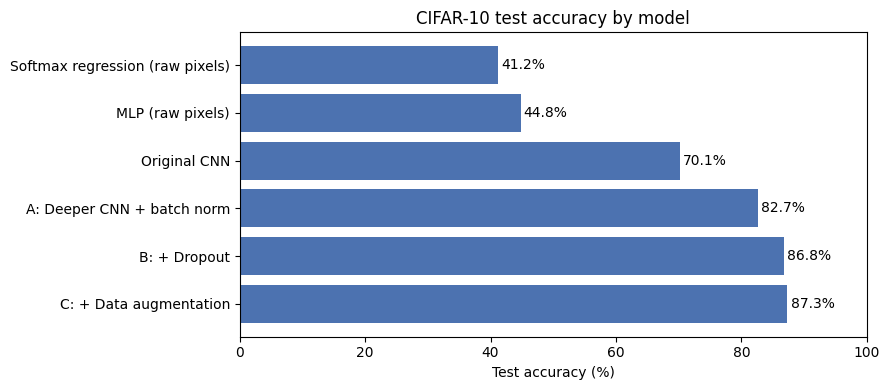

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(results_df["model"], results_df["test_acc"] * 100, color="#4C72B0")
for i, v in enumerate(results_df["test_acc"] * 100):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlabel("Test accuracy (%)")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_title("CIFAR-10 test accuracy by model")
plt.tight_layout()
plt.savefig("test_accuracy_by_model.png", dpi=150)
plt.show()

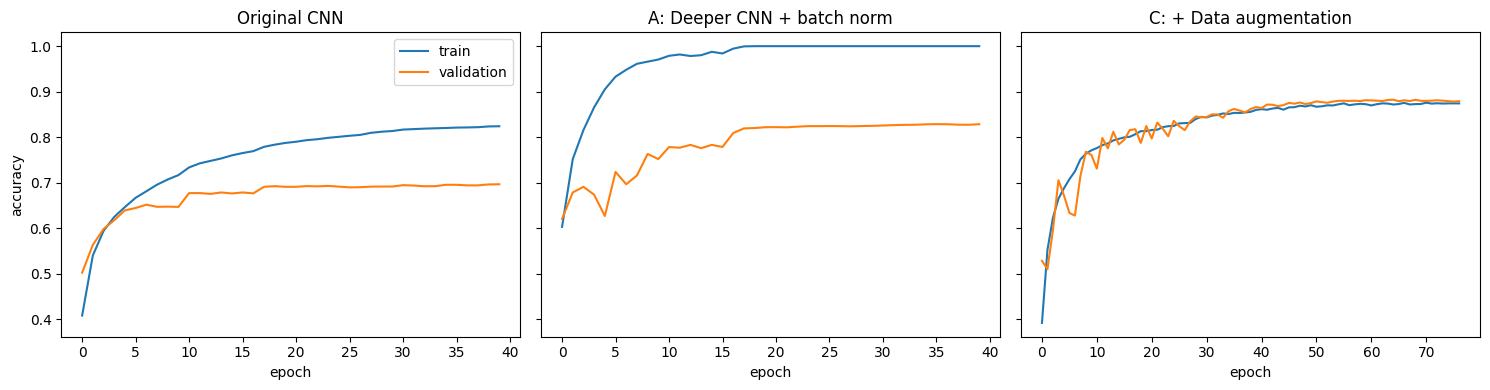

In [13]:
# Training vs. validation accuracy: shows overfitting, and how dropout/augmentation shrink the gap
compare = ["Original CNN", "A: Deeper CNN + batch norm", "C: + Data augmentation"]
fig, axes = plt.subplots(1, len(compare), figsize=(15, 4), sharey=True)
for ax, name in zip(axes, compare):
    h = histories[name]
    ax.plot(h["accuracy"], label="train")
    ax.plot(h["val_accuracy"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

## 7. Error analysis on the best model

Which classes does the final model get wrong, and what does it confuse them with?

Best model: C: + Data augmentation


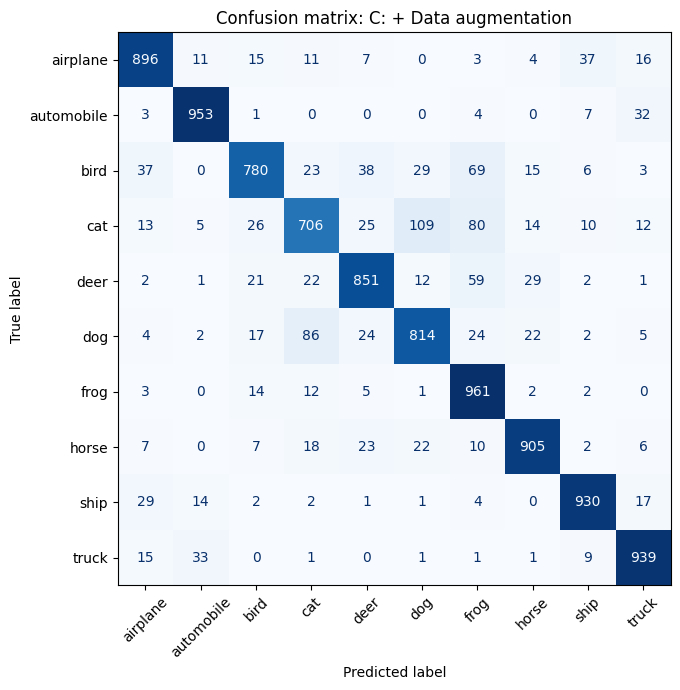

In [14]:
best_name = results_df.loc[results_df["test_acc"].idxmax(), "model"]
best_model = models[best_name]
y_prob = best_model.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)
print("Best model:", best_name)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [15]:
per_class = pd.DataFrame({
    "class": CLASS_NAMES,
    "accuracy_%": (cm.diagonal() / cm.sum(axis=1) * 100).round(1),
}).sort_values("accuracy_%")
print(per_class.to_string(index=False))

# Most frequent confusions (true -> predicted)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
                for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
print("\nTop confusions (count: true -> predicted):")
for n, t, p in pairs:
    print(f"  {n:4d}: {t} -> {p}")

     class  accuracy_%
       cat        70.6
      bird        78.0
       dog        81.4
      deer        85.1
  airplane        89.6
     horse        90.5
      ship        93.0
     truck        93.9
automobile        95.3
      frog        96.1

Top confusions (count: true -> predicted):
   109: cat -> dog
    86: dog -> cat
    80: cat -> frog
    69: bird -> frog
    59: deer -> frog


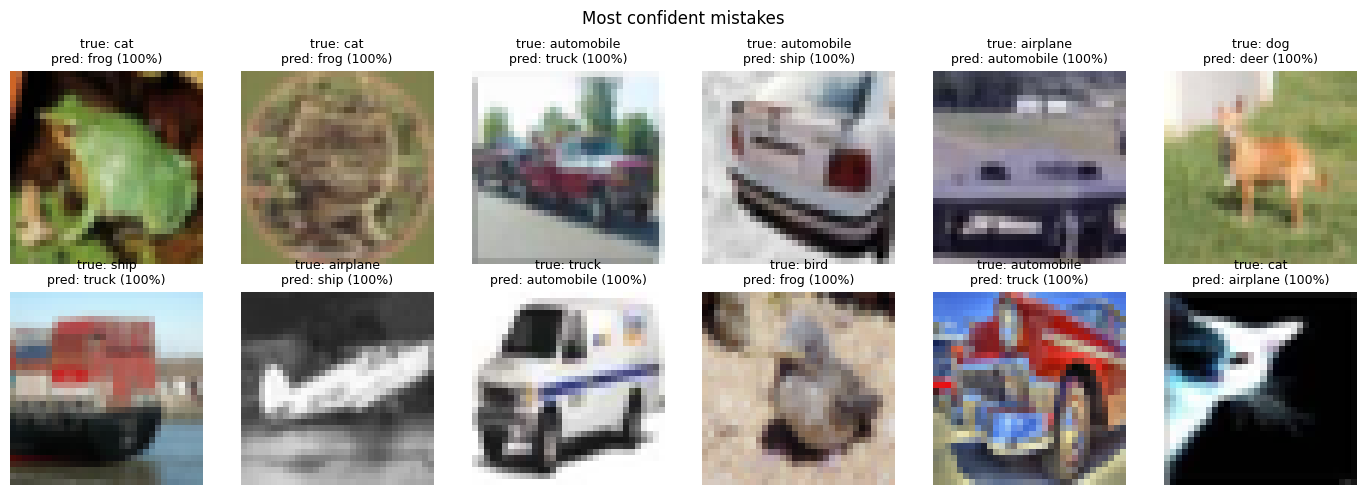

In [16]:
# Look at some of the model's most confident mistakes
wrong = np.where(y_pred != y_test)[0]
conf = y_prob[wrong, y_pred[wrong]]
top_wrong = wrong[np.argsort(-conf)[:12]]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), top_wrong):
    ax.imshow(x_test[i])
    ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[y_pred[i]]} "
                 f"({y_prob[i, y_pred[i]]:.0%})", fontsize=9)
    ax.axis("off")
plt.suptitle("Most confident mistakes")
plt.tight_layout()
plt.savefig("confident_mistakes.png", dpi=150)
plt.show()

## 8. Summary numbers for the writeup and resume

In [17]:
r = results_df.set_index("model")["test_acc"] * 100
summary = f"""
Softmax regression baseline : {r['Softmax regression (raw pixels)']:.1f}%
MLP baseline                : {r['MLP (raw pixels)']:.1f}%
Original CNN                : {r['Original CNN']:.1f}%
Final CNN ({best_name})     : {r[best_name]:.1f}%
Gain over original CNN      : +{r[best_name] - r['Original CNN']:.1f} points
Gain over MLP baseline      : +{r[best_name] - r['MLP (raw pixels)']:.1f} points
Hardest class               : {per_class.iloc[0]['class']} ({per_class.iloc[0]['accuracy_%']}%)
Top confusion               : {pairs[0][1]} -> {pairs[0][2]} ({pairs[0][0]} images)
"""
print(summary)
results_df.to_csv("results.csv", index=False)


Softmax regression baseline : 41.2%
MLP baseline                : 44.8%
Original CNN                : 70.1%
Final CNN (C: + Data augmentation)     : 87.3%
Gain over original CNN      : +17.2 points
Gain over MLP baseline      : +42.6 points
Hardest class               : cat (70.6%)
Top confusion               : cat -> dog (109 images)

